# Financial News Sentiment Prediction using Deep Learning & BERT

**Complete implementation in one notebook · 20 steps · macOS Jupyter / Google Colab**

This notebook loads the specified dataset, checks its quality, trains Simple RNN and LSTM models from scratch, fine-tunes pretrained BERT, compares frozen models, reloads a saved model for inference, and generates a Streamlit app, CLI, README, and a two-page PDF comparison report. Those supporting files are created automatically when you run the notebook; no separately supplied source files are required.

**Execution status at delivery:** Full training outputs are intentionally blank. The accompanying validation record at the end describes checks actually performed. Run all cells in order to obtain your own dataset counts, scores, charts, and saved models. No predicted accuracy or fabricated model results are included.

**Accuracy:** 100% held-out prediction accuracy is not a defensible promise. This implementation optimizes development macro F1 and reports actual official-validation accuracy, macro F1, precision, and recall. Dataset labels can be ambiguous or noisy.

**Before running:**
- On your Mac, open this file in Jupyter with a Python 3.11 or 3.12 kernel. Apple Silicon can use MPS; an Intel Mac uses CPU. BERT may train slowly locally.
- In Colab, upload this file and choose **Runtime → Change runtime type → GPU** before running all cells. The notebook remains portable to CPU.
- Installation and the first dataset/model downloads require internet access. No Hugging Face login or API key is needed for the default public resources.
- Run the dependency cell first. If Jupyter requests a kernel restart after installation, restart and then run from the configuration cell onward.
- Step 2 lets you change the output folder. Colab storage is temporary: download the generated ZIP or save it to your own mounted Drive before ending the session.

**Run modes:** `RUN_MODE = "full"` is the default and uses all eligible training data. `"smoke"` uses small training/development subsets and one epoch to verify the pipeline; its metrics must not be presented as final project performance. Official validation remains separate in both modes.

**Evaluation contract:** Fit preprocessing on training only. Tune and select the deployment model using an internal development split. Freeze that selection before accessing final validation results. The dataset supplies no separate test split, so final results are called **official-validation results**, not independently verified test performance.


## 1. Define the project scope and success criteria

**Objective:** Predict Bearish, Bullish, or Neutral sentiment for English financial tweets.

**Workflow:** Record the dataset, model choices, labels, and primary metric.

**Professional insight:** Define evaluation criteria before seeing model scores. Include BERT because it appears in the requested comparison deliverables.


In [2]:
project_config = {
    "project_name": "Financial News Sentiment Prediction",
    "dataset_id": "zeroshot/twitter-financial-news-sentiment",
    "primary_metric": "macro_f1",
    "supporting_metrics": ["accuracy", "precision_per_class", "recall_per_class"],
    "baseline_models": ["Simple RNN", "LSTM"],
    "include_bert": True,
}
label_names = {0: "Bearish", 1: "Bullish", 2: "Neutral"}
print("Project:", project_config["project_name"])
print("Classes:", ", ".join(label_names.values()))
print("Primary metric:", project_config["primary_metric"])


Project: Financial News Sentiment Prediction
Classes: Bearish, Bullish, Neutral
Primary metric: macro_f1


**Code explanation:** The dictionaries centralize names and the label convention from the project brief.

**Expected output:** The project name, three classes, and `macro_f1`; these are configuration values, not measured results.

**Validation:** The cell should run without installing anything. Step 3 checks the loaded label values.


## 2. Set up a reproducible project

**Objective:** Install libraries, set seeds, detect hardware, and create a separate output directory for each run.

**Workflow:** Install into the active notebook kernel, import libraries, then configure the experiment.

**Professional insight:** Prefer a dedicated local environment. Seeds help repeatability, but CPU, GPU, and MPS results need not be bit-for-bit identical.


In [3]:
# Set the MPS fallback before importing PyTorch.
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import gc
import json
import math
import platform
import random
import re
import shlex
import shutil
import sys
import time
import unicodedata
from collections import Counter
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display, FileLink
from datasets import load_dataset
from huggingface_hub import HfApi
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          get_linear_schedule_with_warmup)

RUN_MODE = "full"  # Change to "smoke" only for a quick pipeline check.
OUTPUT_BASE = Path.cwd() / "financial_sentiment_outputs"
config = {
    "seed": 42, "dev_fraction": 0.15, "run_mode": RUN_MODE,
    "dataset_revision": "ccbe24de388e287beb92dd393a335c376b350ac3",  # Verified source revision.
    "bert_model_id": "google-bert/bert-base-uncased",
    "bert_revision": None,
    "max_vocabulary": 20000, "min_token_frequency": 2,
    "embedding_dim": 128, "hidden_dim": 128, "dropout": 0.3,
    "rnn_batch_size": 64, "rnn_epochs": 12,
    "rnn_learning_rates": [1e-3, 3e-4],
    "bert_batch_size": 8, "bert_epochs": 3, "bert_learning_rate": 2e-5,
    "bert_max_length": 128, "bert_gradient_accumulation": 2,
    "patience": 3, "min_delta": 1e-4, "weight_decay": 0.01,
    "use_class_weights": True, "force_cpu": False,
}
if RUN_MODE not in {"full", "smoke"}:
    raise ValueError("RUN_MODE must be 'full' or 'smoke'.")
if RUN_MODE == "smoke":
    config.update(rnn_epochs=1, bert_epochs=1, rnn_learning_rates=[1e-3])

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(config["seed"])
if config["force_cpu"]:
    device = torch.device("cpu")
elif torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

run_id = datetime.now(timezone.utc).strftime("run-%Y%m%dT%H%M%S%fZ")
RUN_DIR = OUTPUT_BASE / run_id
MODELS_DIR = RUN_DIR / "models"
REPORTS_DIR = RUN_DIR / "reports"
for directory in (MODELS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)
training_records, histories, rnn_architectures = {}, {}, {}
sns.set_theme(style="whitegrid")
print("Python:", platform.python_version(), "| PyTorch:", torch.__version__)
print("Training device:", device, "| Run mode:", RUN_MODE)
print("Output directory:", RUN_DIR.resolve())


Python: 3.14.8 | PyTorch: 2.14.1
Training device: mps | Run mode: full
Output directory: /Users/sundharamurali/Documents/Code/py-projects/financial Sentiment Analysis/financial_sentiment_outputs/run-20261028T210449644034Z


**Code explanation:** `%pip` installs into the notebook kernel. CUDA is preferred, then Apple MPS, then CPU. Each run receives a new folder so earlier results are retained.

**Expected output:** Installed-library status, the selected device, run mode, and a local output path. BERT downloads and training happen later.

**Validation:** For unsupported MPS operations, set `force_cpu=True` and rerun. For GPU memory errors, reduce `bert_batch_size` to 4 or 2. Restart after dependency changes if imports behave unexpectedly.


## 3. Load the specified dataset

**Objective:** Inspect the actual schema and counts rather than assuming those printed in the brief.

**Workflow:** Resolve a dataset revision, load official splits, display the training schema, and validate fields.

**Professional insight:** The dataset card and project brief contain inconsistent counts. Report the rows you actually load and pin their revision.


In [4]:
try:
    if config["dataset_revision"] is None:
        config["dataset_revision"] = HfApi().dataset_info(project_config["dataset_id"]).sha
    raw_dataset = load_dataset(project_config["dataset_id"],
                               revision=config["dataset_revision"])
except Exception as error:
    raise RuntimeError("Dataset download failed. Check internet access and rerun this cell.") from error

if not {"train", "validation"}.issubset(raw_dataset.keys()):
    raise ValueError(f"Expected train/validation splits; found {list(raw_dataset.keys())}.")
print("Dataset revision:", config["dataset_revision"])
display(pd.DataFrame({"Split": list(raw_dataset.keys()),
                      "Rows": [len(raw_dataset[key]) for key in raw_dataset]}))
print("Observed features:", raw_dataset["train"].features)
raw_train_df = raw_dataset["train"].to_pandas()
raw_validation_df = raw_dataset["validation"].to_pandas()
display(raw_train_df.head(3))

# Only choose these names after inspecting the downloaded schema above.
required_columns = {"text", "label"}
for split_name, frame in (("train", raw_train_df), ("validation", raw_validation_df)):
    if not required_columns.issubset(frame.columns):
        raise ValueError(f"{split_name} columns are {list(frame.columns)}; inspect the schema.")
    if frame["label"].isna().any() or not frame["label"].isin(label_names).all():
        raise ValueError(f"{split_name} contains missing or unexpected sentiment labels.")
    if set(frame["label"].unique()) != set(label_names):
        raise ValueError(f"{split_name} does not contain all three expected classes.")
feature = raw_dataset["train"].features["label"]
if hasattr(feature, "names"):
    print("Dataset-provided label names:", feature.names)
print("Label convention from dataset card:", label_names)


Dataset revision: ccbe24de388e287beb92dd393a335c376b350ac3


,Split,Rows
0,train,9543
1,validation,2388


Observed features: {'text': Value('string'), 'label': Value('int64')}


,text,label
0,$BYND - JPMorgan reels in expectations on Beyo...,0
1,$CCL $RCL - Nomura points to bookings weakness...,0
2,"$CX - Cemex cut at Credit Suisse, J.P. Morgan ...",0


Label convention from dataset card: {0: 'Bearish', 1: 'Bullish', 2: 'Neutral'}


**Code explanation:** The column checks fail clearly if the public dataset changes. The numeric mapping is documented by the dataset card; feature names are displayed when provided.

**Expected output:** Actual row counts, text and label fields, three training examples, and the resolved SHA. Counts are deliberately not hard-coded.

**Validation:** Both splits must exist and contain only labels 0, 1, and 2. The cell must load the sentiment dataset, not the similarly named topic dataset.


## 4. Audit data quality

**Objective:** Identify malformed examples, duplicates, conflicting labels, and training/validation overlap.

**Workflow:** Build conservative text fingerprints; filter training problems and remove overlapping training rows while preserving official validation rows.

**Professional insight:** This overlap audit uses validation text only, never validation labels to train or select a model. Near duplicates and shared events may still exist.


In [5]:
def text_fingerprint(text):
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"(?<!\w)@\w+", " ", text)
    return re.sub(r"\s+", " ", text).strip().casefold()

def valid_text(value):
    return isinstance(value, str) and bool(text_fingerprint(value))

train_df = raw_train_df[["text", "label"]].copy()
validation_df = raw_validation_df[["text", "label"]].copy()
train_df["source_row"] = raw_train_df.index
validation_df["source_row"] = raw_validation_df.index
invalid_train = ~train_df["text"].map(valid_text)
invalid_validation = ~validation_df["text"].map(valid_text)
if invalid_validation.any():
    raise ValueError("Official validation contains invalid text. Review it before defining exclusions.")
train_df = train_df.loc[~invalid_train].copy()
train_df["fingerprint"] = train_df["text"].map(text_fingerprint)
validation_df["fingerprint"] = validation_df["text"].map(text_fingerprint)

conflict_counts = train_df.groupby("fingerprint")["label"].nunique()
conflict_keys = set(conflict_counts[conflict_counts > 1].index)
conflicting_rows = train_df["fingerprint"].isin(conflict_keys)
removed_conflicting = int(conflicting_rows.sum())
train_df = train_df.loc[~conflicting_rows].copy()
duplicate_rows = int(train_df.duplicated("fingerprint").sum())
train_df = train_df.drop_duplicates("fingerprint", keep="first").copy()
overlap = train_df["fingerprint"].isin(set(validation_df["fingerprint"]))
removed_overlap = int(overlap.sum())
train_df = train_df.loc[~overlap].reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)

audit = {
    "raw_train_rows": len(raw_train_df), "raw_validation_rows": len(raw_validation_df),
    "invalid_training_rows_removed": int(invalid_train.sum()),
    "conflicting_training_rows_removed": removed_conflicting,
    "duplicate_training_rows_removed": duplicate_rows,
    "overlapping_training_rows_removed": removed_overlap,
    "eligible_training_rows": len(train_df),
    "validation_duplicate_rows_retained": int(validation_df.duplicated("fingerprint").sum()),
}
display(pd.DataFrame(audit.items(), columns=["Check", "Count"]))
assert len(validation_df) == len(raw_validation_df)
assert not set(train_df["fingerprint"]) & set(validation_df["fingerprint"])
assert not train_df["fingerprint"].duplicated().any()
assert set(train_df["label"]) == {0, 1, 2}
(RUN_DIR / "data_audit.json").write_text(json.dumps(audit, indent=2))


,Check,Count
0,raw_train_rows,9543
1,raw_validation_rows,2388
2,invalid_training_rows_removed,6
3,conflicting_training_rows_removed,4
4,duplicate_training_rows_removed,105
5,overlapping_training_rows_removed,32
6,eligible_training_rows,9396
7,validation_duplicate_rows_retained,11


302

**Code explanation:** A fingerprint removes URLs and mentions and normalizes case/spacing while preserving the financial statement. All conflicting training copies are excluded rather than arbitrarily relabeled.

**Expected output:** A table containing actual exclusions. Official validation stays intact, including any duplicates it originally contains.

**Validation:** The assertions verify no remaining fingerprint overlap and no duplicated training fingerprints. Review high exclusion counts before training.


## 5. Perform exploratory data analysis

**Objective:** Understand class imbalance and text lengths using eligible training data.

**Workflow:** Summarize class counts and lengths, inspect examples, and save two plots.

**Professional insight:** Use training data for design decisions. Final-validation labels remain outside exploratory model development.


,Sentiment,Count,Percentage
0,Bearish,1420,15.11
1,Bullish,1905,20.27
2,Neutral,6071,64.61


,Characters
count,9396.000000
mean,85.758834
std,35.057950
min,2.000000
50%,79.000000
90%,139.000000
95%,140.000000
99%,140.000000
max,190.000000


,text,label
0,$BYND - JPMorgan reels in expectations on Beyo...,0
1,$CCL $RCL - Nomura points to bookings weakness...,0
126,$ALTG: Dougherty & Company starts at Buy,1
127,$AMD - AMD's Navi shows strong adoption - BofA...,1
358,$LB - MKM Partners puts a number on Victoria's...,2
359,$WING - Baird returns to Wingstop bull camp ht...,2


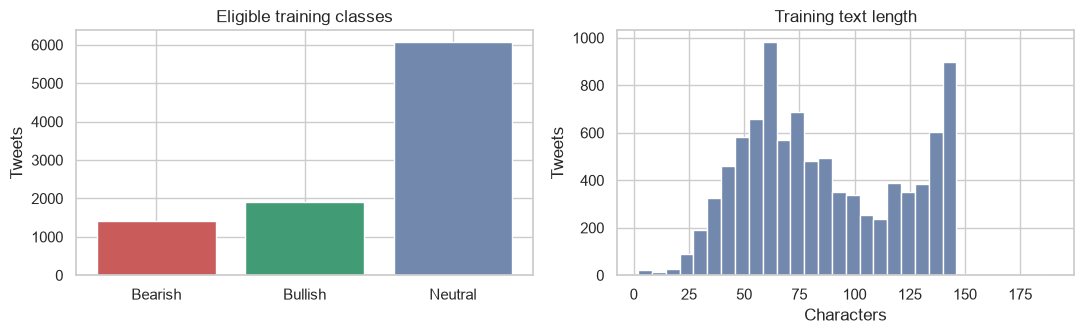

In [6]:
train_distribution = train_df["label"].value_counts().reindex([0, 1, 2], fill_value=0)
eda_table = pd.DataFrame({"Sentiment": [label_names[i] for i in range(3)],
                          "Count": train_distribution.values})
eda_table["Percentage"] = (100 * eda_table["Count"] / len(train_df)).round(2)
display(eda_table)
character_lengths = train_df["text"].str.len()
display(character_lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame("Characters"))
display(train_df.groupby("label", group_keys=False).head(2)[["text", "label"]])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(eda_table["Sentiment"], eda_table["Count"], color=["#c95b5b", "#419c75", "#7388ad"])
axes[0].set(title="Eligible training classes", ylabel="Tweets")
axes[1].hist(character_lengths, bins=30, color="#7388ad")
axes[1].set(title="Training text length", xlabel="Characters", ylabel="Tweets")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "training_eda.png", dpi=160)
plt.show()


**Code explanation:** The distribution reveals whether accuracy could hide weak minority-class performance. The histograms describe text size without making tokenization assumptions.

**Expected output:** A class table, length summary, sample tweets, and two plots; all numbers are computed from your loaded data.

**Validation:** Counts should sum to eligible training rows. All three sentiments should appear.


## 6. Establish the evaluation strategy

**Objective:** Separate model fitting, checkpoint selection, and final evaluation.

**Workflow:** Create a stratified internal development subset from eligible official training data and save the split membership.

**Professional insight:** Select the deployment model using development macro F1 before revealing official-validation scores. No separate official test data exists here.


In [7]:
fit_df, dev_df = train_test_split(train_df, test_size=config["dev_fraction"],
                                 stratify=train_df["label"], random_state=config["seed"])
fit_df = fit_df.reset_index(drop=True)
dev_df = dev_df.reset_index(drop=True)
if RUN_MODE == "smoke":
    # Fixed stratified subsets, used only to verify execution.
    if len(fit_df) > 192:
        fit_df, _ = train_test_split(fit_df, train_size=192, stratify=fit_df["label"],
                                    random_state=config["seed"])
    if len(dev_df) > 96:
        dev_df, _ = train_test_split(dev_df, train_size=96, stratify=dev_df["label"],
                                    random_state=config["seed"])
    fit_df, dev_df = fit_df.reset_index(drop=True), dev_df.reset_index(drop=True)
    print("SMOKE RUN: subset metrics are execution checks, not final project results.")

for first, second in ((fit_df, dev_df), (fit_df, validation_df), (dev_df, validation_df)):
    assert not set(first["fingerprint"]) & set(second["fingerprint"])
display(pd.DataFrame({"Purpose": ["Fit weights", "Tune/select", "Final official validation"],
                      "Rows": [len(fit_df), len(dev_df), len(validation_df)]}))
split_membership = pd.concat([
    frame[["source_row"]].assign(split=name)
    for name, frame in (("fit", fit_df), ("development", dev_df), ("validation", validation_df))
], ignore_index=True)
split_membership.to_csv(RUN_DIR / "split_membership.csv", index=False)


,Purpose,Rows
0,Fit weights,7986
1,Tune/select,1410
2,Final official validation,2388


**Code explanation:** Stratification retains approximate class proportions. `fit_df`, `dev_df`, and `validation_df` have distinct purposes throughout the notebook.

**Expected output:** Three actual split sizes and, in smoke mode, an explicit warning about subset results.

**Validation:** No fingerprints should overlap. Development and fitting subsets must each contain all three classes.


## 7. Build a finance-aware cleaning pipeline

**Objective:** Remove irrelevant links and mentions while retaining meaningful financial language.

**Workflow:** Define shared text cleaning and tokenization, then apply light cleaning to fitting and development text.

**Professional insight:** Preserve negation, cashtags, contractions, percentages, and numbers. Do not stem or remove stopwords for BERT.


In [8]:
import re
import unicodedata


def clean_text(text):
    """Light cleaning shared by training, evaluation, and inference."""
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"(?<!\w)@\w+", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def tokenize_text(text):
    """Retain cashtags, words, contractions, numbers, and meaningful symbols."""
    return re.findall(
        r"\$[A-Za-z][A-Za-z0-9.]*|[A-Za-z]+(?:'[A-Za-z]+)?|"
        r"[-+]?\d+(?:[.,]\d+)*%?|[^\w\s]",
        clean_text(text).lower(),
    )


def encode_texts(texts, vocabulary, max_length):
    """Create padded IDs and masks; empty cleaned input receives UNK."""
    input_ids = np.zeros((len(texts), max_length), dtype=np.int64)
    attention_mask = np.zeros_like(input_ids)
    for row, text in enumerate(texts):
        tokens = tokenize_text(text)[:max_length]
        ids = [vocabulary.get(token, 1) for token in tokens] or [1]
        input_ids[row, :len(ids)] = ids
        attention_mask[row, :len(ids)] = 1
    return torch.from_numpy(input_ids), torch.from_numpy(attention_mask)


In [9]:
for frame in (fit_df, dev_df):
    frame["clean_text"] = frame["text"].map(clean_text)
    assert frame["clean_text"].str.len().gt(0).all()
display(fit_df[["text", "clean_text"]].head(3))
example_text = "$AAPL earnings are not down 10%! https://example.com @analyst"
print("Cleaned demonstration:", clean_text(example_text))
print("Tokens:", tokenize_text(example_text))
assert "$aapl" in tokenize_text(example_text)
assert "not" in tokenize_text(example_text)
assert "10%" in tokenize_text(example_text)


,text,clean_text
0,PPG Industries stock price target raised to $1...,PPG Industries stock price target raised to $1...
1,$ROKU - Roku jumps as optimism builds for earn...,$ROKU - Roku jumps as optimism builds for earn...
2,"HP Is Playing Hard To Get, But Its Rejection C...","HP Is Playing Hard To Get, But Its Rejection C..."


Cleaned demonstration: $AAPL earnings are not down 10%!
Tokens: ['$aapl', 'earnings', 'are', 'not', 'down', '10%', '!']


**Code explanation:** BERT receives lightly cleaned, case-preserving text; its uncased tokenizer handles case. The RNN tokenizer lowercases and explicitly retains financial symbols.

**Expected output:** Before/after training examples and tokens for a synthetic demonstration, which has no sentiment label or claimed prediction.

**Validation:** Negation, `$aapl`, and `10%` must survive. Removing only URLs and mentions must not create empty examples in these splits.


## 8. Create a simple reference baseline

**Objective:** Measure how a majority-class rule performs on development data.

**Workflow:** Fit a DummyClassifier using fitting labels and evaluate it on the internal development split.

**Professional insight:** A high majority-class accuracy is not enough; macro F1 exposes missing performance on other classes.


In [10]:
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(np.zeros((len(fit_df), 1)), fit_df["label"])
dummy_dev_predictions = dummy_model.predict(np.zeros((len(dev_df), 1)))
dummy_dev_accuracy = accuracy_score(dev_df["label"], dummy_dev_predictions)
dummy_dev_f1 = f1_score(dev_df["label"], dummy_dev_predictions, labels=[0, 1, 2],
                         average="macro", zero_division=0)
print(f"Majority baseline | dev accuracy: {dummy_dev_accuracy:.4f} | dev macro F1: {dummy_dev_f1:.4f}")


Majority baseline | dev accuracy: 0.6461 | dev macro F1: 0.2617


**Code explanation:** This model learns only the most frequent fitting label. It establishes a simple reference and does not satisfy the two neural-model requirement.

**Expected output:** Measured development accuracy and macro F1. Values are not known until you run the cell.

**Validation:** Every prediction should equal the fitting set’s most frequent label.


## 9. Prepare inputs for the RNN models

**Objective:** Build a fitting-only vocabulary and prepare tensors for fitting/development.

**Workflow:** Count tokens, reserve PAD and UNK, choose a fitting-derived length limit, and create loaders.

**Professional insight:** Do not fit vocabulary or sequence-length choices on development or official-validation text.


In [11]:
token_counts = Counter(token for text in fit_df["clean_text"] for token in tokenize_text(text))
vocabulary = {"<PAD>": 0, "<UNK>": 1}
for token, count in token_counts.most_common(config["max_vocabulary"] - 2):
    if count >= config["min_token_frequency"]:
        vocabulary[token] = len(vocabulary)
fit_token_lengths = np.array([len(tokenize_text(text)) for text in fit_df["clean_text"]])
rnn_max_length = int(np.clip(np.ceil(np.quantile(fit_token_lengths, 0.98)), 16, 128))

def make_rnn_dataset(frame):
    input_ids, attention_mask = encode_texts(frame["text"].tolist(), vocabulary, rnn_max_length)
    labels = torch.tensor(frame["label"].to_numpy(), dtype=torch.long)
    return TensorDataset(input_ids, attention_mask, labels)

rnn_fit_dataset = make_rnn_dataset(fit_df)
rnn_dev_dataset = make_rnn_dataset(dev_df)
def make_loader(dataset, batch_size, shuffle=False):
    generator = torch.Generator().manual_seed(config["seed"])
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      generator=generator, num_workers=0)

rnn_dev_loader = make_loader(rnn_dev_dataset, config["rnn_batch_size"])
(RUN_DIR / "vocabulary.json").write_text(json.dumps(vocabulary, indent=2))
print("Vocabulary size:", len(vocabulary), "| RNN maximum tokens:", rnn_max_length)
print("Fitting tensor shape:", tuple(rnn_fit_dataset.tensors[0].shape))
print("Fitting truncation fraction:", round(float((fit_token_lengths > rnn_max_length).mean()), 4))
assert rnn_fit_dataset.tensors[0].max().item() < len(vocabulary)
assert rnn_fit_dataset.tensors[1].sum(dim=1).min().item() >= 1


Vocabulary size: 6930 | RNN maximum tokens: 28
Fitting tensor shape: (7986, 28)
Fitting truncation fraction: 0.0183


**Code explanation:** PAD is 0 and UNK is 1. The 98th percentile limits excess padding; the cap bounds memory. A mask distinguishes actual tokens from padding.

**Expected output:** Actual vocabulary size, length limit, tensor dimensions, and truncation fraction.

**Validation:** Token IDs must fit inside the vocabulary; each row must contain at least one unmasked token. Unknown tokens should map to 1.


## 10. Implement Simple RNN

**Objective:** Build the first required model from randomly initialized embeddings and recurrent weights.

**Workflow:** Define a reusable RNN/LSTM class and inspect a Simple RNN forward pass.

**Professional insight:** Use masked pooling so padding does not enter the final representation. Sharing the classifier code makes the architecture comparison easier to understand.


In [12]:
class RecurrentClassifier(nn.Module):
    """A shared embedding/classifier around either Simple RNN or LSTM."""

    def __init__(self, vocabulary_size, embedding_dim=128, hidden_dim=128,
                 dropout=0.3, recurrent_type="rnn", num_classes=3):
        super().__init__()
        if recurrent_type not in {"rnn", "lstm"}:
            raise ValueError("recurrent_type must be 'rnn' or 'lstm'.")
        self.embedding = nn.Embedding(vocabulary_size, embedding_dim, padding_idx=0)
        recurrent_layer = nn.RNN if recurrent_type == "rnn" else nn.LSTM
        self.recurrent = recurrent_layer(embedding_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, num_classes)

    def forward(self, input_ids, attention_mask):
        embedded = self.embedding(input_ids)
        outputs, _ = self.recurrent(embedded)
        # A forward-only recurrent layer plus masking excludes padded positions.
        mask = attention_mask.unsqueeze(-1).to(outputs.dtype)
        pooled = (outputs * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        return self.classifier(self.dropout(pooled))


In [13]:
base_architecture = {"vocabulary_size": len(vocabulary),
                     "embedding_dim": config["embedding_dim"],
                     "hidden_dim": config["hidden_dim"],
                     "dropout": config["dropout"], "num_classes": 3}
set_seed(config["seed"])
simple_rnn_demo = RecurrentClassifier(**base_architecture, recurrent_type="rnn")
demo_ids, demo_mask, _ = next(iter(rnn_dev_loader))
with torch.no_grad():
    demo_logits = simple_rnn_demo(demo_ids[:2], demo_mask[:2])
print(simple_rnn_demo)
print("Output shape:", tuple(demo_logits.shape))
assert demo_logits.shape == (2, 3)
del simple_rnn_demo


RecurrentClassifier(
  (embedding): Embedding(6930, 128, padding_idx=0)
  (recurrent): RNN(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=128, out_features=3, bias=True)
)
Output shape: (2, 3)


**Code explanation:** The embedding turns IDs into vectors; the recurrent layer reads them in order; masked pooling summarizes valid positions. The output is three logits, converted to probabilities only when needed.

**Expected output:** The architecture and output shape `(2, 3)`. These random logits are not trained predictions.

**Validation:** There must be one logit per class for each example. Cross-entropy receives logits, not pre-applied softmax.


## 11. Implement LSTM

**Objective:** Build the second required model under the same input and classifier settings.

**Workflow:** Instantiate the shared class with an LSTM recurrent layer and inspect its shape.

**Professional insight:** LSTM gates can preserve information across longer sequences, but improved performance must be demonstrated rather than assumed.


In [14]:
set_seed(config["seed"])
lstm_demo = RecurrentClassifier(**base_architecture, recurrent_type="lstm")
with torch.no_grad():
    lstm_logits = lstm_demo(demo_ids[:2], demo_mask[:2])
print(lstm_demo)
print("Output shape:", tuple(lstm_logits.shape))
print("Trainable parameters:", sum(p.numel() for p in lstm_demo.parameters() if p.requires_grad))
assert lstm_logits.shape == (2, 3)
del lstm_demo


RecurrentClassifier(
  (embedding): Embedding(6930, 128, padding_idx=0)
  (recurrent): LSTM(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=128, out_features=3, bias=True)
)
Output shape: (2, 3)
Trainable parameters: 1019523


**Code explanation:** Changing the recurrent type retains the same embeddings, pooling, class labels, and fitting/development examples.

**Expected output:** The LSTM architecture, `(2, 3)` output shape, and its parameter count.

**Validation:** The recurrent layer should be an LSTM. Its parameter count can differ from Simple RNN even with the same hidden dimension.


## 12. Train both RNN models systematically

**Objective:** Create shared training/evaluation functions with early stopping and gradient clipping.

**Workflow:** Compute class weights using fitting labels, then train each architecture at the first planned learning rate.

**Professional insight:** Use development macro F1 to save the best checkpoint. A weighted loss changes training emphasis; metrics remain unweighted across examples.


In [15]:
fit_class_counts = fit_df["label"].value_counts().reindex([0, 1, 2], fill_value=0)
if (fit_class_counts == 0).any():
    raise ValueError("The fitting subset must contain each class.")
if config["use_class_weights"]:
    class_weights = torch.tensor(len(fit_df) / (3 * fit_class_counts.to_numpy()), dtype=torch.float32)
else:
    class_weights = torch.ones(3, dtype=torch.float32)
display(pd.DataFrame({"Sentiment": list(label_names.values()),
                      "Fit count": fit_class_counts.values, "Loss weight": class_weights.numpy()}))


,Sentiment,Fit count,Loss weight
0,Bearish,1207,2.205468
1,Bullish,1619,1.644225
2,Neutral,5160,0.515891


In [16]:
def forward_logits(model, input_ids, attention_mask, model_family):
    if model_family == "bert":
        return model(input_ids=input_ids, attention_mask=attention_mask).logits
    return model(input_ids, attention_mask)


def run_epoch(model, loader, criterion, model_family, optimizer=None,
              scheduler=None, gradient_accumulation=1):
    training = optimizer is not None
    model.train(training)
    all_labels, all_probabilities = [], []
    loss_total, sample_count = 0.0, 0
    if training:
        optimizer.zero_grad(set_to_none=True)

    for batch_index, (input_ids, attention_mask, labels) in enumerate(loader):
        input_ids, attention_mask, labels = (
            input_ids.to(device), attention_mask.to(device), labels.to(device)
        )
        with torch.set_grad_enabled(training):
            logits = forward_logits(model, input_ids, attention_mask, model_family)
            loss = criterion(logits, labels)
            if training:
                group_start = (batch_index // gradient_accumulation) * gradient_accumulation
                group_size = min(gradient_accumulation, len(loader) - group_start)
                (loss / group_size).backward()
                update_now = ((batch_index + 1) % gradient_accumulation == 0
                              or batch_index + 1 == len(loader))
                if update_now:
                    nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                    optimizer.step()
                    if scheduler is not None:
                        scheduler.step()
                    optimizer.zero_grad(set_to_none=True)

        probabilities = torch.softmax(logits.detach(), dim=-1).cpu().numpy()
        all_labels.extend(labels.detach().cpu().tolist())
        all_probabilities.append(probabilities)
        loss_total += loss.item() * len(labels)
        sample_count += len(labels)

    if sample_count == 0:
        raise ValueError("A data loader is empty; inspect the split and filtering.")
    probabilities = np.concatenate(all_probabilities)
    labels = np.asarray(all_labels)
    predicted = probabilities.argmax(axis=1)
    return {
        "loss": loss_total / sample_count,
        "accuracy": accuracy_score(labels, predicted),
        "macro_f1": f1_score(labels, predicted, labels=[0, 1, 2],
                             average="macro", zero_division=0),
        "labels": labels, "probabilities": probabilities,
    }


def train_model(model, model_name, model_family, train_loader, dev_loader,
                learning_rate, max_epochs, gradient_accumulation=1):
    """Select checkpoints using development macro F1, never final validation."""
    set_seed(config["seed"])
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate,
                                 weight_decay=config["weight_decay"])
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
    scheduler = None
    if model_family == "bert":
        total_updates = math.ceil(len(train_loader) / gradient_accumulation) * max_epochs
        scheduler = get_linear_schedule_with_warmup(
            optimizer, num_warmup_steps=int(0.1 * total_updates),
            num_training_steps=total_updates,
        )

    checkpoint_path = MODELS_DIR / f"{model_name}_best.pt"
    best_f1, wait = -1.0, 0
    history = []
    started = time.perf_counter()
    for epoch in range(1, max_epochs + 1):
        train_metrics = run_epoch(model, train_loader, criterion, model_family,
                                  optimizer, scheduler, gradient_accumulation)
        dev_metrics = run_epoch(model, dev_loader, criterion, model_family)
        history.append({
            "epoch": epoch, "train_loss": train_metrics["loss"],
            "dev_loss": dev_metrics["loss"], "train_macro_f1": train_metrics["macro_f1"],
            "dev_macro_f1": dev_metrics["macro_f1"],
            "dev_accuracy": dev_metrics["accuracy"],
        })
        print(f"{model_name} | epoch {epoch:02d} | "
              f"train loss {train_metrics['loss']:.4f} | "
              f"dev macro F1 {dev_metrics['macro_f1']:.4f}")
        if dev_metrics["macro_f1"] > best_f1 + config["min_delta"]:
            best_f1 = dev_metrics["macro_f1"]
            wait = 0
            cpu_state = {key: value.detach().cpu().clone()
                         for key, value in model.state_dict().items()}
            torch.save(cpu_state, checkpoint_path)
            del cpu_state
        else:
            wait += 1
            if wait >= config["patience"]:
                print("Early stopping: development macro F1 stopped improving.")
                break
        pd.DataFrame(history).to_csv(REPORTS_DIR / f"{model_name}_history.csv", index=False)

    elapsed = time.perf_counter() - started
    model.load_state_dict(torch.load(checkpoint_path, map_location="cpu", weights_only=True))
    model.eval()
    best_metrics = run_epoch(model, dev_loader, criterion, model_family)
    training_records[model_name] = {
        "model_family": model_family, "dev_macro_f1": best_metrics["macro_f1"],
        "dev_accuracy": best_metrics["accuracy"], "training_seconds": elapsed,
        "epochs_completed": len(history), "learning_rate": learning_rate,
        "checkpoint": str(checkpoint_path),
    }
    histories[model_name] = pd.DataFrame(history)
    return model


In [17]:
first_learning_rate = config["rnn_learning_rates"][0]
for architecture_name, recurrent_type in (("SimpleRNN", "rnn"), ("LSTM", "lstm")):
    model_name = f"{architecture_name}_lr{first_learning_rate:g}"
    architecture = {**base_architecture, "recurrent_type": recurrent_type}
    rnn_architectures[model_name] = architecture
    set_seed(config["seed"])
    model = RecurrentClassifier(**architecture)
    train_loader = make_loader(rnn_fit_dataset, config["rnn_batch_size"], shuffle=True)
    model = train_model(model, model_name, "rnn", train_loader, rnn_dev_loader,
                        first_learning_rate, config["rnn_epochs"])
    del model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    elif device.type == "mps":
        torch.mps.empty_cache()


SimpleRNN_lr0.001 | epoch 01 | train loss 1.0032 | dev macro F1 0.5307
SimpleRNN_lr0.001 | epoch 02 | train loss 0.8436 | dev macro F1 0.5867
SimpleRNN_lr0.001 | epoch 03 | train loss 0.7120 | dev macro F1 0.6007
SimpleRNN_lr0.001 | epoch 04 | train loss 0.5916 | dev macro F1 0.6208
SimpleRNN_lr0.001 | epoch 05 | train loss 0.4857 | dev macro F1 0.6463
SimpleRNN_lr0.001 | epoch 06 | train loss 0.3881 | dev macro F1 0.6627
SimpleRNN_lr0.001 | epoch 07 | train loss 0.3083 | dev macro F1 0.6642
SimpleRNN_lr0.001 | epoch 08 | train loss 0.2355 | dev macro F1 0.6593
SimpleRNN_lr0.001 | epoch 09 | train loss 0.1801 | dev macro F1 0.6574
SimpleRNN_lr0.001 | epoch 10 | train loss 0.1286 | dev macro F1 0.6662
SimpleRNN_lr0.001 | epoch 11 | train loss 0.0914 | dev macro F1 0.6806
SimpleRNN_lr0.001 | epoch 12 | train loss 0.0675 | dev macro F1 0.6785
LSTM_lr0.001 | epoch 01 | train loss 0.9914 | dev macro F1 0.5198
LSTM_lr0.001 | epoch 02 | train loss 0.7663 | dev macro F1 0.6420
LSTM_lr0.001 | e

**Code explanation:** The common loop handles fitting and development, clips gradients, logs losses/F1, and restores the best saved weights. The same loop later trains BERT with a scheduler.

**Expected output:** Actual per-epoch loss and development macro F1, followed by early stopping when applicable. Checkpoints and histories appear in the run directory.

**Validation:** Losses and scores should be finite. If loss becomes NaN, stop and inspect inputs or reduce learning rate. Do not alter settings after examining final validation.


## 13. Tune RNN models on development data

**Objective:** Compare a small predefined learning-rate grid without touching final validation.

**Workflow:** Train the remaining planned trials, select the best RNN trial for each architecture, and plot histories.

**Professional insight:** The full run compares two learning rates per architecture. Smoke mode checks one rate only; it is not a tuning experiment.


SimpleRNN_lr0.0003 | epoch 01 | train loss 1.0629 | dev macro F1 0.4972
SimpleRNN_lr0.0003 | epoch 02 | train loss 0.9513 | dev macro F1 0.5097
SimpleRNN_lr0.0003 | epoch 03 | train loss 0.8755 | dev macro F1 0.5543
SimpleRNN_lr0.0003 | epoch 04 | train loss 0.8182 | dev macro F1 0.5493
SimpleRNN_lr0.0003 | epoch 05 | train loss 0.7715 | dev macro F1 0.5777
SimpleRNN_lr0.0003 | epoch 06 | train loss 0.7285 | dev macro F1 0.5919
SimpleRNN_lr0.0003 | epoch 07 | train loss 0.6860 | dev macro F1 0.5925
SimpleRNN_lr0.0003 | epoch 08 | train loss 0.6436 | dev macro F1 0.6020
SimpleRNN_lr0.0003 | epoch 09 | train loss 0.6067 | dev macro F1 0.6056
SimpleRNN_lr0.0003 | epoch 10 | train loss 0.5672 | dev macro F1 0.6101
SimpleRNN_lr0.0003 | epoch 11 | train loss 0.5332 | dev macro F1 0.6242
SimpleRNN_lr0.0003 | epoch 12 | train loss 0.4967 | dev macro F1 0.6117
LSTM_lr0.0003 | epoch 01 | train loss 1.0747 | dev macro F1 0.4697
LSTM_lr0.0003 | epoch 02 | train loss 0.9516 | dev macro F1 0.5265
LS

,dev_macro_f1,dev_accuracy,learning_rate,epochs_completed
LSTM_lr0.001,0.687928,0.765248,0.001,12
SimpleRNN_lr0.001,0.680644,0.763121,0.001,12
LSTM_lr0.0003,0.65901,0.74539,0.0003,12
SimpleRNN_lr0.0003,0.624199,0.709929,0.0003,12


Development-selected RNN trials: {'SimpleRNN': 'SimpleRNN_lr0.001', 'LSTM': 'LSTM_lr0.001'}


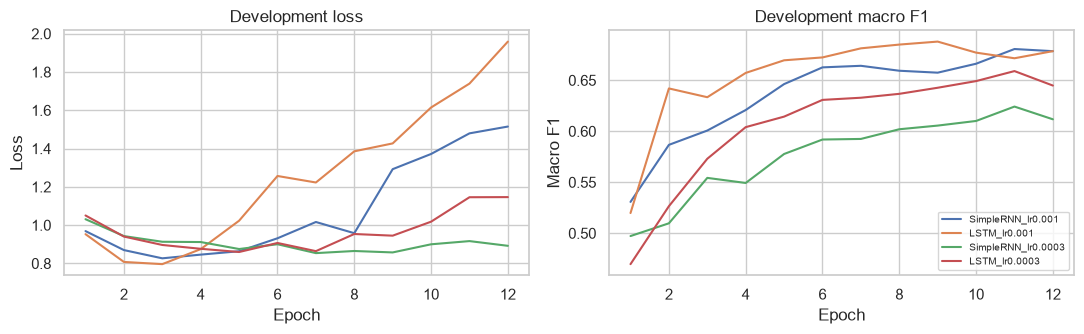

In [18]:
for learning_rate in config["rnn_learning_rates"][1:]:
    for architecture_name, recurrent_type in (("SimpleRNN", "rnn"), ("LSTM", "lstm")):
        model_name = f"{architecture_name}_lr{learning_rate:g}"
        architecture = {**base_architecture, "recurrent_type": recurrent_type}
        rnn_architectures[model_name] = architecture
        set_seed(config["seed"])
        model = RecurrentClassifier(**architecture)
        loader = make_loader(rnn_fit_dataset, config["rnn_batch_size"], shuffle=True)
        model = train_model(model, model_name, "rnn", loader, rnn_dev_loader,
                            learning_rate, config["rnn_epochs"])
        del model
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()
        elif device.type == "mps":
            torch.mps.empty_cache()

rnn_trials_df = pd.DataFrame(training_records).T.sort_values("dev_macro_f1", ascending=False)
display(rnn_trials_df[["dev_macro_f1", "dev_accuracy", "learning_rate", "epochs_completed"]])
best_rnn_names = {
    architecture: max((name for name in training_records if name.startswith(architecture + "_")),
                      key=lambda name: training_records[name]["dev_macro_f1"])
    for architecture in ("SimpleRNN", "LSTM")
}
print("Development-selected RNN trials:", best_rnn_names)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, history in histories.items():
    axes[0].plot(history["epoch"], history["dev_loss"], label=name)
    axes[1].plot(history["epoch"], history["dev_macro_f1"], label=name)
axes[0].set(title="Development loss", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Development macro F1", xlabel="Epoch", ylabel="Macro F1")
axes[1].legend(fontsize=7)
fig.tight_layout()
fig.savefig(REPORTS_DIR / "rnn_training_curves.png", dpi=160)
plt.show()


**Code explanation:** Each trial has its own checkpoint. The selected Simple RNN and LSTM settings maximize development macro F1 within the predefined grid.

**Expected output:** A measured development comparison, chosen trial names, and learning curves.

**Validation:** Both architectures must have a selected checkpoint. Overfitting appears when fitting performance rises while development performance stalls.


## 14. Prepare the BERT experiment

**Objective:** Tokenize the same fitting/development examples for a pretrained BERT encoder.

**Workflow:** Resolve the checkpoint revision, tokenize with its matching tokenizer, and initialize a three-class head.

**Professional insight:** Use the original BERT checkpoint rather than a public classifier already fine-tuned on this evaluation dataset. Its broad pretraining does not prove absence of all corpus overlap.


In [19]:
try:
    if config["bert_revision"] is None:
        config["bert_revision"] = HfApi().model_info(config["bert_model_id"]).sha
    bert_tokenizer = AutoTokenizer.from_pretrained(config["bert_model_id"],
                                                  revision=config["bert_revision"])
    set_seed(config["seed"])
    bert_model = AutoModelForSequenceClassification.from_pretrained(
        config["bert_model_id"], revision=config["bert_revision"], num_labels=3,
        id2label=label_names, label2id={name: index for index, name in label_names.items()},
    )
except Exception as error:
    raise RuntimeError("BERT download failed. Check connectivity and available disk space.") from error

def make_bert_dataset(frame):
    encoded = bert_tokenizer(frame["text"].map(clean_text).tolist(),
                             padding="max_length", truncation=True,
                             max_length=config["bert_max_length"], return_tensors="pt")
    labels = torch.tensor(frame["label"].to_numpy(), dtype=torch.long)
    return TensorDataset(encoded["input_ids"], encoded["attention_mask"], labels)

bert_fit_dataset = make_bert_dataset(fit_df)
bert_dev_dataset = make_bert_dataset(dev_df)
bert_fit_loader = make_loader(bert_fit_dataset, config["bert_batch_size"], shuffle=True)
bert_dev_loader = make_loader(bert_dev_dataset, config["bert_batch_size"])
print("BERT checkpoint:", config["bert_model_id"])
print("BERT revision:", config["bert_revision"])
print("Fitting tensor shape:", tuple(bert_fit_dataset.tensors[0].shape))
print("Classification labels:", bert_model.config.id2label)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


BERT checkpoint: google-bert/bert-base-uncased
BERT revision: 86b5e0934494bd15c9632b12f734a8a67f723594
Fitting tensor shape: (7986, 128)
Classification labels: {0: 'Bearish', 1: 'Bullish', 2: 'Neutral'}


**Code explanation:** The pretrained encoder has learned language structure; its new three-class head is randomly initialized. The warning about newly initialized classifier weights is expected before fine-tuning.

**Expected output:** Download progress, checkpoint revision, tensor shape, and Bearish/Bullish/Neutral label mapping.

**Validation:** The classification head must have three outputs. The same source rows and labels must feed BERT and both recurrent models.


## 15. Fine-tune BERT

**Objective:** Adapt all BERT weights to financial sentiment and save the development-selected checkpoint.

**Workflow:** Use the shared loop with a smaller learning rate, warmup schedule, gradient accumulation, and early stopping.

**Professional insight:** Float32 is used for portability. A Colab GPU is usually more practical than CPU for this step; runtime depends on hardware and batch size.


In [20]:
bert_model = train_model(bert_model, "BERT", "bert", bert_fit_loader, bert_dev_loader,
                          config["bert_learning_rate"], config["bert_epochs"],
                          config["bert_gradient_accumulation"])
bert_artifact_dir = MODELS_DIR / "bert"
bert_model.save_pretrained(bert_artifact_dir, safe_serialization=True)
bert_tokenizer.save_pretrained(bert_artifact_dir)
# Remove only the intermediate checkpoint created by this run; exported weights remain.
Path(training_records["BERT"]["checkpoint"]).unlink()
training_records["BERT"]["checkpoint"] = str(bert_artifact_dir)
del bert_model
gc.collect()
if device.type == "cuda":
    torch.cuda.empty_cache()
elif device.type == "mps":
    torch.mps.empty_cache()

development_results = pd.DataFrame(training_records).T.sort_values("dev_macro_f1", ascending=False)
display(development_results[["dev_macro_f1", "dev_accuracy", "training_seconds", "epochs_completed"]])
candidate_names = [best_rnn_names["SimpleRNN"], best_rnn_names["LSTM"], "BERT"]
selected_model_name = max(candidate_names, key=lambda name: training_records[name]["dev_macro_f1"])
print("Deployment model selected BEFORE final validation:", selected_model_name)
(RUN_DIR / "config.json").write_text(json.dumps(config, indent=2))
(RUN_DIR / "training_records.json").write_text(json.dumps(training_records, indent=2))


BERT | epoch 01 | train loss 0.7228 | dev macro F1 0.7986
BERT | epoch 02 | train loss 0.3674 | dev macro F1 0.8421
BERT | epoch 03 | train loss 0.1988 | dev macro F1 0.8335


,dev_macro_f1,dev_accuracy,training_seconds,epochs_completed
BERT,0.842061,0.874468,1289.557424,3
LSTM_lr0.001,0.687928,0.765248,13.405465,12
SimpleRNN_lr0.001,0.680644,0.763121,19.044108,12
LSTM_lr0.0003,0.65901,0.74539,13.192608,12
SimpleRNN_lr0.0003,0.624199,0.709929,18.984746,12


Deployment model selected BEFORE final validation: BERT


2067

**Code explanation:** The deployment choice is frozen using development macro F1. Exported BERT weights and tokenizer are sufficient for later offline inference.

**Expected output:** Measured BERT training logs, all development scores, and the selected deployment model. No improvement is assumed.

**Validation:** Confirm `models/bert/config.json`, model weights, and tokenizer files exist. Memory errors should be addressed before retrying this cell.


## 16. Run the final model comparison

**Objective:** Evaluate the frozen Simple RNN, LSTM, and BERT candidates on identical official-validation rows.

**Workflow:** Build validation tensors only now, load saved checkpoints, calculate class-wise metrics, and save comparisons.

**Professional insight:** Treat these as final official-validation results. Do not retune after inspecting them or switch the deployment model using these scores.


In [21]:
rnn_validation_dataset = make_rnn_dataset(validation_df)
bert_validation_dataset = make_bert_dataset(validation_df)
validation_results = {}
comparison_rows = []
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
for name in candidate_names:
    family = training_records[name]["model_family"]
    if family == "bert":
        model = AutoModelForSequenceClassification.from_pretrained(bert_artifact_dir, local_files_only=True)
        loader = make_loader(bert_validation_dataset, config["bert_batch_size"])
    else:
        model = RecurrentClassifier(**rnn_architectures[name])
        model.load_state_dict(torch.load(MODELS_DIR / f"{name}_best.pt",
                                        map_location="cpu", weights_only=True))
        loader = make_loader(rnn_validation_dataset, config["rnn_batch_size"])
    model = model.to(device).eval()
    # Warm up the backend so startup is not counted as inference throughput.
    warm_ids, warm_mask, _ = next(iter(loader))
    with torch.inference_mode():
        forward_logits(model, warm_ids[:1].to(device), warm_mask[:1].to(device), family)
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()
    started = time.perf_counter()
    result = run_epoch(model, loader, criterion, family)
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()
    elapsed = time.perf_counter() - started
    validation_results[name] = result
    predicted = result["probabilities"].argmax(axis=1)
    report = classification_report(result["labels"], predicted, labels=[0, 1, 2],
                                    target_names=list(label_names.values()),
                                    output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(REPORTS_DIR / f"{name}_classification_report.csv")
    np.savez_compressed(REPORTS_DIR / f"{name}_validation_predictions.npz",
                        labels=result["labels"], probabilities=result["probabilities"])
    comparison_rows.append({
        "Model": name, "Run_mode": RUN_MODE,
        "Dev_macro_F1": training_records[name]["dev_macro_f1"],
        "Validation_accuracy": result["accuracy"], "Validation_macro_F1": result["macro_f1"],
        "Training_minutes": training_records[name]["training_seconds"] / 60,
        "Evaluation_ms_per_tweet": 1000 * elapsed / len(validation_df),
    })
    del model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    elif device.type == "mps":
        torch.mps.empty_cache()

dummy_validation_predictions = dummy_model.predict(np.zeros((len(validation_df), 1)))
dummy_final = {"accuracy": accuracy_score(validation_df["label"], dummy_validation_predictions),
               "macro_f1": f1_score(validation_df["label"], dummy_validation_predictions,
                                     labels=[0, 1, 2], average="macro", zero_division=0)}
comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)
display(comparison_df.round(4))
print("Majority baseline official-validation scores:", dummy_final)
best_rnn_final_f1 = max(validation_results[name]["macro_f1"] for name in best_rnn_names.values())
bert_f1_difference = validation_results["BERT"]["macro_f1"] - best_rnn_final_f1
print(f"BERT minus best RNN validation macro F1: {bert_f1_difference:+.4f} "
      f"({100 * bert_f1_difference:+.2f} percentage points)")
print("Deployment selection remains:", selected_model_name)


,Model,Run_mode,Dev_macro_F1,Validation_accuracy,Validation_macro_F1,Training_minutes,Evaluation_ms_per_tweet
0,SimpleRNN_lr0.001,full,0.6806,0.7626,0.6731,0.3174,0.0563
1,LSTM_lr0.001,full,0.6879,0.7705,0.6821,0.2234,0.0422
2,BERT,full,0.8421,0.8639,0.8294,21.4926,12.5587


Majority baseline official-validation scores: {'accuracy': 0.6557788944723618, 'macro_f1': 0.26403641881638845}
BERT minus best RNN validation macro F1: +0.1473 (+14.73 percentage points)
Deployment selection remains: BERT


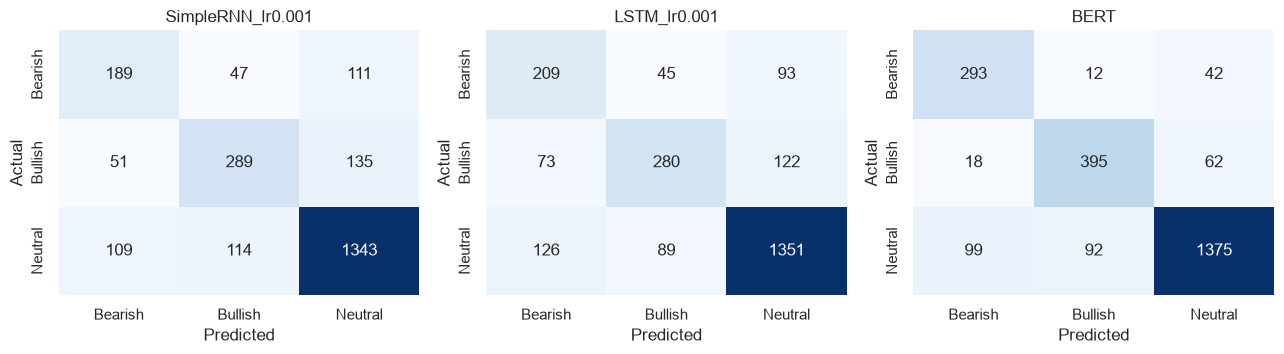

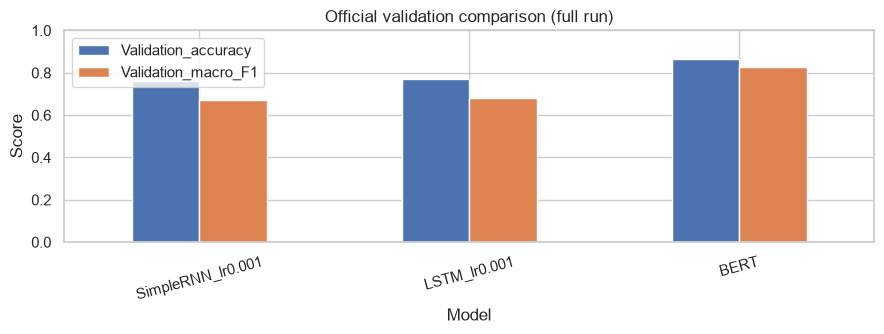

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
for axis, name in zip(axes, candidate_names):
    result = validation_results[name]
    matrix = confusion_matrix(result["labels"], result["probabilities"].argmax(axis=1), labels=[0, 1, 2])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis,
                xticklabels=list(label_names.values()), yticklabels=list(label_names.values()))
    axis.set(title=name, xlabel="Predicted", ylabel="Actual")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "confusion_matrices.png", dpi=160)
plt.show()

fig, axis = plt.subplots(figsize=(9, 3.5))
comparison_df.set_index("Model")[["Validation_accuracy", "Validation_macro_F1"]].plot.bar(ax=axis)
axis.set(ylim=(0, 1), title=f"Official validation comparison ({RUN_MODE} run)", ylabel="Score")
axis.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(REPORTS_DIR / "model_comparison.png", dpi=160)
plt.show()


**Code explanation:** All candidates use the same validation labels. The speed measurement is average batched evaluation time including loss/metric overhead and excluding tokenization; it is not single-request app latency.

**Expected output:** Real comparison scores, three class-wise CSV reports, confusion matrices, and a signed BERT-minus-RNN difference.

**Validation:** Probabilities must have shape `(validation_rows, 3)` and sum to approximately 1. A negative BERT difference must be reported as a decrease.


## 17. Analyze prediction errors

**Objective:** Explain mistakes with concrete examples rather than relying only on aggregate metrics.

**Workflow:** Inspect the preselected model’s confusion pairs, class metrics, and confident errors.

**Professional insight:** Automatic error categories can be misleading. Write qualitative conclusions only after reading examples; probabilities are not calibrated confidence guarantees.


In [23]:
selected_result = validation_results[selected_model_name]
selected_predictions = selected_result["probabilities"].argmax(axis=1)
error_analysis_df = validation_df[["source_row", "text", "label"]].copy()
error_analysis_df["Actual"] = error_analysis_df["label"].map(label_names)
error_analysis_df["Predicted"] = pd.Series(selected_predictions).map(label_names)
error_analysis_df["Max_probability"] = selected_result["probabilities"].max(axis=1)
errors_df = error_analysis_df.loc[selected_predictions != validation_df["label"].to_numpy()]
errors_df = errors_df.sort_values("Max_probability", ascending=False).reset_index(drop=True)
errors_df.to_csv(REPORTS_DIR / "selected_model_errors.csv", index=False)
print("Selected model:", selected_model_name, "| Errors:", len(errors_df), "of", len(validation_df))
display(errors_df[["text", "Actual", "Predicted", "Max_probability"]].head(10))
if not errors_df.empty:
    display(pd.crosstab(errors_df["Actual"], errors_df["Predicted"]))
selected_class_report = classification_report(
    selected_result["labels"], selected_predictions, labels=[0, 1, 2],
    target_names=list(label_names.values()), output_dict=True, zero_division=0,
)
display(pd.DataFrame(selected_class_report).T.round(4))


Selected model: BERT | Errors: 325 of 2388


,text,Actual,Predicted,Max_probability
0,5 Reasons To Love Wendy's On Its 50th Birthday,Bullish,Neutral,0.989333
1,Stock Market News: Netflix Climbs on Subscribe...,Neutral,Bullish,0.989327
2,These Stocks Could Bounce High in January and ...,Neutral,Bullish,0.988575
3,$ITRN - Margins suffer at Ituran Location in Q...,Neutral,Bearish,0.988308
4,US Proved Oil & Gas Reserves Hit New Record High,Bearish,Bullish,0.988268
5,Yields head lower despite strong economic numbers,Neutral,Bearish,0.985314
6,YTD Performance:\nDow Jones: Red\n30Y: +9%\n\n...,Neutral,Bullish,0.985010
7,Publicis Signals Worst May Be Over for Struggl...,Bullish,Bearish,0.984494
8,Press release: cyber attack - update January 3...,Bearish,Neutral,0.983101
9,Zimbabwe to the IMF: “Our fundamentals are now...,Bullish,Neutral,0.983083


Predicted,Bearish,Bullish,Neutral
Actual,,,
Bearish,0,12,42
Bullish,18,0,62
Neutral,99,92,0


,precision,recall,f1-score,support
Bearish,0.7146,0.8444,0.7741,347.0000
Bullish,0.7916,0.8316,0.8111,475.0000
Neutral,0.9297,0.8780,0.9031,1566.0000
accuracy,0.8639,0.8639,0.8639,0.8639
macro avg,0.8120,0.8513,0.8294,2388.0000
weighted avg,0.8710,0.8639,0.8661,2388.0000


**Code explanation:** The error table ranks mismatches by their largest predicted probability. Inspect negation, mixed sentiment, earnings expectations, and ticker-specific context manually.

**Expected output:** Actual mismatches and class metrics, or an empty error table if no mismatches occur. No causes are invented automatically.

**Validation:** Each listed row must have different actual and predicted labels. Validation error inspection is for reporting, not further fitting.


## 18. Build and verify saved-model inference

**Objective:** Reload the frozen deployment model from disk and expose one consistent prediction interface.

**Workflow:** Write a manifest and a standalone core module, then compare reloaded predictions to evaluation outputs.

**Professional insight:** The tokenizer, class order, vocabulary, and preprocessing are part of the model artifact. Paragraphs are accepted, but evaluated tweet performance does not establish paragraph accuracy.


In [24]:
manifest = {
    "project": project_config, "config": config, "run_mode": RUN_MODE,
    "selected_model": selected_model_name,
    "selection_basis": "Internal development macro F1, frozen before official validation",
    "model_family": training_records[selected_model_name]["model_family"],
    "label_names": label_names, "rnn_architectures": rnn_architectures,
    "rnn_max_length": rnn_max_length, "bert_max_length": config["bert_max_length"],
    "validation_rows": len(validation_df), "dummy_validation": dummy_final,
    "bert_minus_best_rnn_validation_macro_f1": bert_f1_difference,
}
(RUN_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))


2445

In [25]:
core_source = '''
import json
import re
import unicodedata
from pathlib import Path
import numpy as np
import torch
from torch import nn
from transformers import AutoTokenizer, AutoModelForSequenceClassification
'''


In [26]:
core_source += r'''

def clean_text(text):
    """Light cleaning shared by training, evaluation, and inference."""
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"(?<!\w)@\w+", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def tokenize_text(text):
    """Retain cashtags, words, contractions, numbers, and meaningful symbols."""
    return re.findall(
        r"\$[A-Za-z][A-Za-z0-9.]*|[A-Za-z]+(?:'[A-Za-z]+)?|"
        r"[-+]?\d+(?:[.,]\d+)*%?|[^\w\s]",
        clean_text(text).lower(),
    )


def encode_texts(texts, vocabulary, max_length):
    """Create padded IDs and masks; empty cleaned input receives UNK."""
    input_ids = np.zeros((len(texts), max_length), dtype=np.int64)
    attention_mask = np.zeros_like(input_ids)
    for row, text in enumerate(texts):
        tokens = tokenize_text(text)[:max_length]
        ids = [vocabulary.get(token, 1) for token in tokens] or [1]
        input_ids[row, :len(ids)] = ids
        attention_mask[row, :len(ids)] = 1
    return torch.from_numpy(input_ids), torch.from_numpy(attention_mask)
'''


In [27]:
core_source += r'''

class RecurrentClassifier(nn.Module):
    """A shared embedding/classifier around either Simple RNN or LSTM."""

    def __init__(self, vocabulary_size, embedding_dim=128, hidden_dim=128,
                 dropout=0.3, recurrent_type="rnn", num_classes=3):
        super().__init__()
        if recurrent_type not in {"rnn", "lstm"}:
            raise ValueError("recurrent_type must be 'rnn' or 'lstm'.")
        self.embedding = nn.Embedding(vocabulary_size, embedding_dim, padding_idx=0)
        recurrent_layer = nn.RNN if recurrent_type == "rnn" else nn.LSTM
        self.recurrent = recurrent_layer(embedding_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, num_classes)

    def forward(self, input_ids, attention_mask):
        embedded = self.embedding(input_ids)
        outputs, _ = self.recurrent(embedded)
        # A forward-only recurrent layer plus masking excludes padded positions.
        mask = attention_mask.unsqueeze(-1).to(outputs.dtype)
        pooled = (outputs * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        return self.classifier(self.dropout(pooled))
'''


In [28]:
core_source += r'''

class SentimentPredictor:
    """Load the selected model from disk for notebook, CLI, or Streamlit use."""

    def __init__(self, artifact_dir, device_name="cpu"):
        self.artifact_dir = Path(artifact_dir).resolve()
        self.device = torch.device(device_name)
        self.manifest = json.loads((self.artifact_dir / "manifest.json").read_text())
        self.model_name = self.manifest["selected_model"]
        self.label_names = {int(key): value for key, value
                            in self.manifest["label_names"].items()}
        self.family = self.manifest["model_family"]
        if self.family == "bert":
            model_dir = self.artifact_dir / "models" / "bert"
            self.tokenizer = AutoTokenizer.from_pretrained(model_dir, local_files_only=True)
            self.model = AutoModelForSequenceClassification.from_pretrained(
                model_dir, local_files_only=True,
            )
            self.max_length = self.manifest["bert_max_length"]
        else:
            self.vocabulary = json.loads((self.artifact_dir / "vocabulary.json").read_text())
            architecture = self.manifest["rnn_architectures"][self.model_name]
            self.model = RecurrentClassifier(**architecture)
            weights_path = self.artifact_dir / "models" / f"{self.model_name}_best.pt"
            self.model.load_state_dict(torch.load(weights_path, map_location="cpu", weights_only=True))
            self.max_length = self.manifest["rnn_max_length"]
        self.model = self.model.to(self.device).eval()

    def predict(self, text):
        if not isinstance(text, str):
            raise TypeError("Input must be a string.")
        cleaned = clean_text(text)
        if not cleaned:
            raise ValueError("Enter meaningful text; URLs and mentions alone are not enough.")
        if self.family == "bert":
            token_count = len(self.tokenizer.encode(cleaned, add_special_tokens=True))
            encoded = self.tokenizer(cleaned, truncation=True, max_length=self.max_length,
                                     padding=True, return_tensors="pt")
            inputs = {key: value.to(self.device) for key, value in encoded.items()}
            with torch.inference_mode():
                logits = self.model(**inputs).logits
        else:
            token_count = len(tokenize_text(cleaned))
            input_ids, attention_mask = encode_texts([cleaned], self.vocabulary, self.max_length)
            with torch.inference_mode():
                logits = self.model(input_ids.to(self.device), attention_mask.to(self.device))
        probabilities = torch.softmax(logits, dim=-1)[0].cpu().numpy()
        predicted_id = int(probabilities.argmax())
        return {
            "model": self.model_name, "sentiment": self.label_names[predicted_id],
            "probabilities": {self.label_names[index]: float(probabilities[index])
                              for index in range(3)},
            "token_count": token_count, "truncated": token_count > self.max_length,
        }
'''


In [29]:
(RUN_DIR / "sentiment_core.py").write_text(core_source)
print("Saved reusable inference code:", RUN_DIR / "sentiment_core.py")


Saved reusable inference code: /Users/sundharamurali/Documents/Code/py-projects/financial Sentiment Analysis/financial_sentiment_outputs/run-20261028T210449644034Z/sentiment_core.py


In [30]:
import importlib.util
core_spec = importlib.util.spec_from_file_location("saved_sentiment_core", RUN_DIR / "sentiment_core.py")
saved_core = importlib.util.module_from_spec(core_spec)
core_spec.loader.exec_module(saved_core)
predictor = saved_core.SentimentPredictor(RUN_DIR, device_name=str(device))
inference_checks = []
for index in range(min(3, len(validation_df))):
    result = predictor.predict(validation_df.iloc[index]["text"])
    reloaded_probs = np.array([result["probabilities"][label_names[i]] for i in range(3)])
    # Single-item vs batched GPU/MPS execution may differ slightly numerically.
    np.testing.assert_allclose(reloaded_probs, selected_result["probabilities"][index], atol=3e-3, rtol=3e-3)
    inference_checks.append({"Text": validation_df.iloc[index]["text"],
                             "Sentiment": result["sentiment"],
                             "Truncated": result["truncated"]})
display(pd.DataFrame(inference_checks))
for invalid_input in ("", "   ", "https://example.com @user"):
    try:
        predictor.predict(invalid_input)
    except ValueError:
        pass
    else:
        raise AssertionError("Empty/URL-only input must be rejected.")
print("Saved-model reload and input checks passed.")

# User-editable demonstration: no ground-truth label is claimed for this text.
user_text = "The company reported stronger earnings but warned about weaker demand next quarter."
display(pd.DataFrame(predictor.predict(user_text)["probabilities"].items(),
                      columns=["Sentiment", "Model probability"]))
print("Predicted sentiment:", predictor.predict(user_text)["sentiment"])


,Text,Sentiment,Truncated
0,$ALLY - Ally Financial pulls outlook https://t...,Bearish,False
1,"$DELL $HPE - Dell, HPE targets trimmed on comp...",Bearish,False
2,$PRTY - Moody's turns negative on Party City h...,Bearish,False


Saved-model reload and input checks passed.


,Sentiment,Model probability
0,Bearish,0.137781
1,Bullish,0.786006
2,Neutral,0.076213


Predicted sentiment: Bullish


**Code explanation:** The exported module contains the same preprocessing and model definition as the notebook. `SentimentPredictor` reloads local artifacts without redownloading weights.

**Expected output:** Reloaded predictions, a passed-check message, and model probabilities for an unlabeled demonstration text.

**Validation:** Reloaded probabilities should match batched evaluation within a small tolerance. Empty/URL-only text should raise a helpful ValueError; long input must report truncation.


## 19. Create the Streamlit dashboard

**Objective:** Provide a simple local app using the same saved inference pipeline.

**Workflow:** Save validation distribution, create an app, and print the launch command without starting a background service.

**Professional insight:** The app defaults to CPU for portable deployment. In Colab, download the run ZIP and launch locally rather than exposing an unreviewed public tunnel.


In [31]:
validation_counts = validation_df["label"].value_counts().reindex([0, 1, 2], fill_value=0)
validation_distribution = pd.DataFrame({"Sentiment": list(label_names.values()),
                                        "Count": validation_counts.values})
validation_distribution.to_csv(REPORTS_DIR / "validation_class_distribution.csv", index=False)


In [32]:
app_source = r'''

from pathlib import Path
import pandas as pd
import streamlit as st
from sentiment_core import SentimentPredictor

ARTIFACT_DIR = Path(__file__).resolve().parent
st.set_page_config(page_title="Financial Sentiment", page_icon="📈", layout="centered")
st.title("Financial News Sentiment")
st.caption("Classify English financial tweets and headlines as Bearish, Bullish, or Neutral.")

@st.cache_resource
def load_predictor():
    return SentimentPredictor(ARTIFACT_DIR, device_name="cpu")

try:
    predictor = load_predictor()
except (OSError, ValueError, RuntimeError) as error:
    st.error(f"Could not load the saved model: {error}")
    st.stop()

st.caption(f"Selected model: {predictor.model_name}")
text = st.text_area("Financial text", height=140,
                    placeholder="Paste a financial tweet, headline, or short paragraph...")
if st.button("Predict sentiment", type="primary"):
    try:
        result = predictor.predict(text)
        st.subheader(result["sentiment"])
        probabilities = pd.DataFrame({
            "Sentiment": list(result["probabilities"]),
            "Probability": list(result["probabilities"].values()),
        }).set_index("Sentiment")
        st.bar_chart(probabilities)
        st.dataframe(probabilities.style.format("{:.1%}"), width="stretch")
        if result["truncated"]:
            st.warning("This input exceeds the model limit; only its beginning was classified.")
        st.caption("Probabilities are model estimates and have not been calibrated.")
    except (TypeError, ValueError) as error:
        st.warning(str(error))

st.subheader("Evaluation sample: class distribution")
distribution = pd.read_csv(ARTIFACT_DIR / "reports" / "validation_class_distribution.csv")
st.bar_chart(distribution.set_index("Sentiment")[["Count"]])
with st.expander("Measured model comparison"):
    st.dataframe(pd.read_csv(ARTIFACT_DIR / "reports" / "model_comparison.csv"),
                 width="stretch")
st.caption("Evaluation used financial tweets. Paragraph generalization needs separate evaluation.")
st.caption("This app estimates sentiment; it does not establish future price direction.")
'''

(RUN_DIR / "streamlit_app.py").write_text(app_source)
print("Run from a local terminal after installing dependencies:")
print(f"{shlex.quote(sys.executable)} -m streamlit run {shlex.quote(str((RUN_DIR / 'streamlit_app.py').resolve()))}")


Run from a local terminal after installing dependencies:
'/Users/sundharamurali/Documents/Code/py-projects/financial Sentiment Analysis/.venv/bin/python' -m streamlit run '/Users/sundharamurali/Documents/Code/py-projects/financial Sentiment Analysis/financial_sentiment_outputs/run-20261028T210449644034Z/streamlit_app.py'


**Code explanation:** The app includes text input, a prediction, class probabilities, a validation-distribution plot, and measured comparisons. Its model is cached after the first load.

**Expected output:** The saved app path and a terminal launch command. A screenshot is only available after launching the app; none is fabricated here.

**Validation:** Test empty input, a financial headline, and a long paragraph. Predictions should match the notebook using the same artifacts.


## 20. Prepare the final deliverables

**Objective:** Generate documentation, a CLI, a measured two-page comparison report, and a downloadable run archive.

**Workflow:** Record package versions and methodology, build the report from computed results, validate required files, and create a ZIP.

**Professional insight:** Keep generated scores tied to their run mode and revisions. The ZIP contains model weights and may be large; the notebook remains the single supplied project source.


In [33]:
cli_source = r'''

import argparse
import json
from pathlib import Path
from sentiment_core import SentimentPredictor

parser = argparse.ArgumentParser(description="Predict financial sentiment using saved artifacts.")
parser.add_argument("text", help="A financial tweet, headline, or paragraph.")
parser.add_argument("--device", default="cpu", choices=["cpu", "mps", "cuda"])
args = parser.parse_args()
try:
    predictor = SentimentPredictor(Path(__file__).resolve().parent, args.device)
    print(json.dumps(predictor.predict(args.text), indent=2))
except (ValueError, TypeError) as error:
    parser.error(str(error))
'''

(RUN_DIR / "predict.py").write_text(cli_source)


604

In [34]:
packages = ["torch", "transformers", "datasets", "scikit-learn", "pandas", "numpy",
            "matplotlib", "seaborn", "streamlit", "reportlab", "huggingface-hub", "ipywidgets"]
package_versions = {package: version(package) for package in packages}
(RUN_DIR / "requirements.txt").write_text(
    "\n".join(f"{package}=={package_versions[package]}" for package in packages) + "\n"
)
environment = {"python": platform.python_version(), "platform": platform.platform(),
               "device": str(device), "packages": package_versions,
               "completed_utc": datetime.now(timezone.utc).isoformat()}
(RUN_DIR / "environment.json").write_text(json.dumps(environment, indent=2))

readme = f"""# Financial News Sentiment Prediction

Run mode: **{RUN_MODE}**. Selected model: **{selected_model_name}**.
Selection used internal development macro F1 before official validation.

## Run locally
Use a dedicated Python 3.11/3.12 environment and open the supplied notebook.
Run all notebook cells in order. Full training requires internet for initial downloads.
Each run creates a new directory with saved models and measured results.

To use this extracted run directory:
```bash
python -m pip install -r requirements.txt
python predict.py 'Company earnings exceeded expectations.'
python -m streamlit run streamlit_app.py
```

## Data and evaluation
- Dataset: {project_config['dataset_id']}
- Dataset revision: {config['dataset_revision']}
- BERT checkpoint/revision: {config['bert_model_id']} / {config['bert_revision']}
- Eligible official-training rows: {len(train_df)}
- Fitting rows used: {len(fit_df)}; development rows used: {len(dev_df)}
- Official-validation rows: {len(validation_df)}; preserved from the source split.
- Training duplicates, conflicts, invalid text, and validation overlap were audited.
- Vocabulary and class weights use fitting data only.
- RNN tuning: {config['rnn_learning_rates']}; early stopping by development macro F1.
- No independent official test split exists. Results are official-validation scores.
- Evaluation milliseconds/tweet is batched evaluation overhead, excluding tokenization.

## Measured comparison
```text
{comparison_df.round(4).to_string(index=False)}
```

BERT minus the best RNN validation macro F1: {bert_f1_difference:+.4f}.
This signed difference is reported even when BERT does not improve.

## Outputs
`models/`: saved neural-model weights and BERT tokenizer.
`manifest.json`, `vocabulary.json`, `config.json`: inference/training settings.
`data_audit.json`, `split_membership.csv`: documented filtering and split membership.
`reports/`: class metrics, predictions, errors, plots, and two-page PDF comparison.
`sentiment_core.py`: shared inference implementation.
`predict.py`: command-line inference; `streamlit_app.py`: dashboard.
`requirements.txt`, `environment.json`: environment versions.

## Limits and presentation notes
No 100% accuracy guarantee. Probabilities have not been calibrated.
Training/validation are financial tweets; paragraph accuracy needs separate evaluation.
The text fingerprint audit catches normalized duplicates, not every shared event.
Pretraining overlap cannot be ruled out. Random seeds do not guarantee identical
results across hardware. Smoke runs verify execution and are not final benchmarks.
Read `reports/selected_model_errors.csv` before explaining likely error causes.
Capture app screenshots after running the dashboard. No screenshots are fabricated.
This classifier measures sentiment; price forecasting is not evaluated.

## References
- https://huggingface.co/datasets/zeroshot/twitter-financial-news-sentiment
- https://huggingface.co/google-bert/bert-base-uncased
- https://huggingface.co/docs/transformers/model_doc/bert
- https://pytorch.org/docs/stable/notes/mps.html
- https://docs.streamlit.io/

The dataset card specifies an MIT license. Review individual dependency and model
licenses before redistribution. This notebook does not upload or publish files.
"""
(RUN_DIR / "README.md").write_text(readme)
print("Saved README, CLI, configuration, and exact top-level package versions.")


Saved README, CLI, configuration, and exact top-level package versions.


In [35]:
from html import escape
from reportlab.lib import colors
from reportlab.lib.enums import TA_LEFT
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import (SimpleDocTemplate, Paragraph, Spacer, Table,
                               TableStyle, Image, PageBreak, KeepInFrame)

report_path = REPORTS_DIR / "comparison_report.pdf"
styles = getSampleStyleSheet()
styles.add(ParagraphStyle(name="Compact", fontSize=8, leading=10, spaceAfter=5))
styles.add(ParagraphStyle(name="SmallCell", fontSize=7, leading=9))
def paragraph(text, style="Compact"):
    return Paragraph(escape(str(text)), styles[style])

page_one = [paragraph("Financial News Sentiment: Model Comparison", "Title"),
            paragraph(f"Run: {RUN_MODE} | Device: {device} | Seed: {config['seed']}"),
            paragraph(f"Task: Bearish / Bullish / Neutral. Fit {len(fit_df)}; development "
                      f"{len(dev_df)}; official validation {len(validation_df)} rows."),
            paragraph("Model performance", "Heading2")]
table_rows = [["Model", "Dev F1", "Val accuracy", "Val macro F1", "Train min"]]
for _, row in comparison_df.iterrows():
    table_rows.append([row["Model"], f"{row['Dev_macro_F1']:.4f}",
                       f"{row['Validation_accuracy']:.4f}",
                       f"{row['Validation_macro_F1']:.4f}",
                       f"{row['Training_minutes']:.2f}"])
table = Table([[paragraph(value, "SmallCell") for value in row] for row in table_rows],
              colWidths=[150, 60, 80, 80, 60], repeatRows=1)
table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#e8eef5")),
    ("GRID", (0, 0), (-1, -1), 0.35, colors.lightgrey),
    ("VALIGN", (0, 0), (-1, -1), "TOP"),
    ("TOPPADDING", (0, 0), (-1, -1), 6),
    ("BOTTOMPADDING", (0, 0), (-1, -1), 6),
]))
page_one += [table, Spacer(1, 12),
             Image(str(REPORTS_DIR / "model_comparison.png"), width=440, height=171),
             paragraph(f"BERT minus best RNN validation macro F1: {bert_f1_difference:+.4f} "
                       f"({100 * bert_f1_difference:+.2f} percentage points)."),
             paragraph(f"Majority rule: validation accuracy {dummy_final['accuracy']:.4f}; "
                       f"macro F1 {dummy_final['macro_f1']:.4f}."),
             paragraph(f"Deployment selection: {selected_model_name}, selected on development "
                       "macro F1 before final validation. No architecture advantage is assumed."),
             paragraph("Methodology", "Heading2"),
             paragraph("Stratified internal development split from official training. "
                       "Fitting-only vocabulary and class weights. Two recurrent architectures "
                       "with a predefined learning-rate grid; BERT fine-tuning with warmup. "
                       "Early stopping and checkpoint selection use development macro F1."),
             paragraph("Data audit: " + "; ".join(f"{key}: {value}" for key, value in audit.items())),
             paragraph(f"Dataset revision: {config['dataset_revision']}"),
             paragraph(f"BERT: {config['bert_model_id']} / {config['bert_revision']}")]

class_rows = [["Class", "Precision", "Recall", "F1", "Support"]]
for name in label_names.values():
    scores = selected_class_report[name]
    class_rows.append([name, f"{scores['precision']:.4f}", f"{scores['recall']:.4f}",
                       f"{scores['f1-score']:.4f}", str(int(scores['support']))])
class_table = Table([[paragraph(value, "SmallCell") for value in row] for row in class_rows],
                    colWidths=[110, 80, 80, 80, 80])
class_table.setStyle(TableStyle([("GRID", (0, 0), (-1, -1), 0.35, colors.lightgrey),
                                ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#e8eef5"))]))
page_two = [paragraph("Error Analysis and Application", "Title"),
            paragraph(f"Selected model: {selected_model_name} | Validation errors: "
                      f"{len(errors_df)} / {len(validation_df)}"), class_table, Spacer(1, 10),
            Image(str(REPORTS_DIR / "confusion_matrices.png"), width=470, height=134),
            paragraph("Examples to inspect", "Heading2")]
if errors_df.empty:
    page_two.append(paragraph("No mismatches found in this run. This does not establish perfect generalization."))
else:
    for _, row in errors_df.head(3).iterrows():
        page_two.append(paragraph(f"Actual {row['Actual']} -> predicted {row['Predicted']} "
                                  f"(max probability {row['Max_probability']:.3f}): {row['text'][:240]}"))
page_two += [paragraph("Interpretation", "Heading2"),
             paragraph("Read the examples before attributing causes. Consider negation, mixed "
                       "sentiment, earnings expectations, and unfamiliar tickers. Model "
                       "probabilities are not calibrated confidence estimates."),
             paragraph("Application", "Heading2"),
             paragraph("The generated Streamlit app accepts financial text and displays its "
                       "sentiment, probabilities, validation distribution, and comparison table. "
                       "It uses the same saved-model inference as the notebook and CLI."),
             paragraph("Limits and reproducibility", "Heading2"),
             paragraph("Official-validation results are not an independent test estimate. "
                       "Training-text fingerprints do not remove all shared-event or near-duplicate "
                       "information. Paragraph generalization and future-price prediction are "
                       "not established. Smoke-mode results are only pipeline checks. Exact "
                       "reproducibility across hardware is not guaranteed. No 100% accuracy promise."),
            paragraph("References: https://huggingface.co/datasets/zeroshot/twitter-financial-news-sentiment; "
                       "https://huggingface.co/google-bert/bert-base-uncased; "
                       "https://huggingface.co/docs/transformers/model_doc/bert."),
             paragraph("Next presentation action: inspect error CSVs and capture screenshots "
                       "after launching the app. Screenshots and qualitative explanations "
                       "are not invented by this report.")]

document = SimpleDocTemplate(str(report_path), pagesize=A4,
                             leftMargin=40, rightMargin=40, topMargin=35, bottomMargin=35)
# Each planned page is bounded to the available frame, so the report stays two pages.
document.build([KeepInFrame(510, 760, page_one, mode="shrink"), PageBreak(),
                KeepInFrame(510, 760, page_two, mode="shrink")])
print("Two-page comparison report:", report_path)


Two-page comparison report: /Users/sundharamurali/Documents/Code/py-projects/financial Sentiment Analysis/financial_sentiment_outputs/run-20261028T210449644034Z/reports/comparison_report.pdf


In [36]:
import ast
for filename in ("sentiment_core.py", "predict.py", "streamlit_app.py"):
    ast.parse((RUN_DIR / filename).read_text())
required_outputs = ["manifest.json", "config.json", "vocabulary.json", "README.md",
                    "requirements.txt", "environment.json", "data_audit.json",
                    "split_membership.csv", "sentiment_core.py", "predict.py", "streamlit_app.py",
                    "reports/model_comparison.csv", "reports/selected_model_errors.csv",
                    "reports/validation_class_distribution.csv", "reports/comparison_report.pdf"]
missing = [name for name in required_outputs if not (RUN_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(f"Missing deliverables: {missing}")
for name, result in validation_results.items():
    assert result["probabilities"].shape == (len(validation_df), 3)
    assert np.isfinite(result["probabilities"]).all()
    np.testing.assert_allclose(result["probabilities"].sum(axis=1), 1, atol=1e-5)

archive_path = Path(shutil.make_archive(str(RUN_DIR), "zip", root_dir=RUN_DIR))
print("Completed run mode:", RUN_MODE)
print("Deployment model:", selected_model_name)
print("All generated deliverable checks passed.")
print("Archive:", archive_path.resolve())
print("Archive size (MB):", round(archive_path.stat().st_size / 1_000_000, 1))
display(FileLink(str(REPORTS_DIR / "comparison_report.pdf")))
display(FileLink(str(archive_path)))
if "google.colab" in sys.modules:
    print("Colab: download the ZIP using the Files panel, or use the optional cell below.")


Completed run mode: full
Deployment model: BERT
All generated deliverable checks passed.
Archive: /Users/sundharamurali/Documents/Code/py-projects/financial Sentiment Analysis/financial_sentiment_outputs/run-20261028T210449644034Z.zip
Archive size (MB): 420.8


/Users/sundharamurali/Documents/Code/py-projects/financial Sentiment Analysis/financial_sentiment_outputs/run-20261028T210449644034Z/reports/comparison_report.pdf

/Users/sundharamurali/Documents/Code/py-projects/financial Sentiment Analysis/financial_sentiment_outputs/run-20261028T210449644034Z.zip

In [37]:
# Optional Colab download; enable only after the full notebook has finished.
DOWNLOAD_ARCHIVE = False
if DOWNLOAD_ARCHIVE and "google.colab" in sys.modules:
    from google.colab import files
    files.download(str(archive_path))


**Code explanation:** The final cells generate the report from actual scores and errors, record exact package versions, validate outputs, and zip all runtime artifacts.

**Expected output:** A completed-run summary and links to the generated report and ZIP. The ZIP is produced only after successful execution.

**Validation:** Read the PDF, inspect charts, run the CLI and Streamlit locally, and use full-mode results for submission. Publish or upload your repository only when you choose to do so.


## References and final presentation checklist

- [Dataset and documented label convention](https://huggingface.co/datasets/zeroshot/twitter-financial-news-sentiment)
- [Default pretrained BERT checkpoint](https://huggingface.co/google-bert/bert-base-uncased)
- [BERT model API](https://huggingface.co/docs/transformers/model_doc/bert)
- [PyTorch MPS notes](https://pytorch.org/docs/stable/notes/mps.html)
- [Streamlit documentation](https://docs.streamlit.io/)

Explain the problem, actual dataset counts, cleaning choices, leakage prevention, architectural differences, development-based selection, final-validation results, and observed errors. Distinguish measured findings from possible explanations. Capture app screenshots after launch. The generated report deliberately does not fabricate screenshots or causal error explanations.

**Notebook completion:** All 20 implementation steps are supplied. Successful completion of training and execution is established only by running the cells and obtaining the final passed-check message. Blank output cells at delivery do not imply that training has already happened.


## Verification performed before delivery

Checked on 14 October 2026 using an isolated Python 3.12 environment. These checks validate execution paths; they do not establish final predictive performance.

- Notebook structure validated, all code cells parsed, and dependency-cell notebook syntax checked.
- The specified public dataset was downloaded at revision `ccbe24de388e287beb92dd393a335c376b350ac3`: **9,543 training rows and 2,388 validation rows**. Counts were measured rather than copied from the inconsistent brief.
- The audit found 6 invalid training texts, 4 training rows with conflicting labels, 105 further duplicate training rows, and 32 training/validation overlaps to exclude. It retained 9,396 eligible training rows and preserved official validation, including 11 duplicated validation rows.
- **36 project code cells** were executed in a temporary integration run. It used 192 fitting tweets, 96 development tweets, one epoch per RNN trial, and a tiny randomly initialized local BERT fixture to exercise BERT training and serialization. Both configured learning rates for Simple RNN and LSTM were tested. The official-validation rows were preserved.
- Reloaded inference passed for Simple RNN, LSTM, and the BERT fixture, including non-string, empty, and long inputs. The CLI returned a prediction in a separate Python process.
- Streamlit's application test rendered the dashboard, ran a prediction, and checked invalid-input handling.
- The report generator produced two pages; rendered sample pages were visually checked for legibility and clipping. All expected runtime files and the ZIP were generated successfully.

**Not executed:** Full-data training, downloading and fine-tuning the full-size pretrained BERT checkpoint, and final benchmark measurement. The delivered notebook defaults to full mode and the pretrained BERT checkpoint; it does not contain the tiny test fixture or its scores. Run the notebook to generate genuine model results on your hardware. No 100% accuracy claim is made.
